In [ ]:
# Imports
import pandas as pd
import os
import matplotlib.pyplot as plt
import textwrap

In [4]:
# The notebook runs from cmu_tare_model/, like the main notebook
OUTPUT_FOLDER_PATH = "output_results"
COMPARISON_PATH = os.path.join(
    OUTPUT_FOLDER_PATH, "scenario_results_comparison.csv"
)

# Read time stamps as text, since result file names use them exactly
df_comparison = pd.read_csv(COMPARISON_PATH, dtype={"datetime": str})

# Oldest first (these time stamps sort as text)
RUN_DATETIMES = sorted(df_comparison["datetime"].unique())

print(f"{len(RUN_DATETIMES)} unique run(s): {RUN_DATETIMES}")

3 unique run(s): ['2026-10-30_11-37', '2026-10-30_12-26', '2026-11-02_14-31']


In [ ]:
df_comparison.columns

Index(['datetime', 'location', 'description', 'logged at',
       'total homes included (rdu)', 'homes considered for adoption (rdu)',
       'MP', 'Scenario', 'Adopters (rdu)', 'Adopters (% of rdu)',
       'Adopters (% weighted)', 'Annual consumption (GWh)',
       'Absolute annual peak (MW)', 'Summer peak (MW)', 'Winter peak (MW)'],
      dtype='object')

In [ ]:
#Compares metrics for baseline scenarios across runs

baseline_metrics = [
    'total homes included (rdu)', 
    'homes considered for adoption (rdu)',
    'Annual consumption (GWh)',
    'Absolute annual peak (MW)', 
    'Summer peak (MW)', 
    'Winter peak (MW)',
]

# A run can be logged more than once; keep its last Baseline row
df_baseline = (
    df_comparison[df_comparison["Scenario"] == "Baseline"]
    .sort_values("logged at")
    .drop_duplicates(subset="datetime", keep="last")
    .sort_values("datetime")
    .reset_index(drop=True)
)

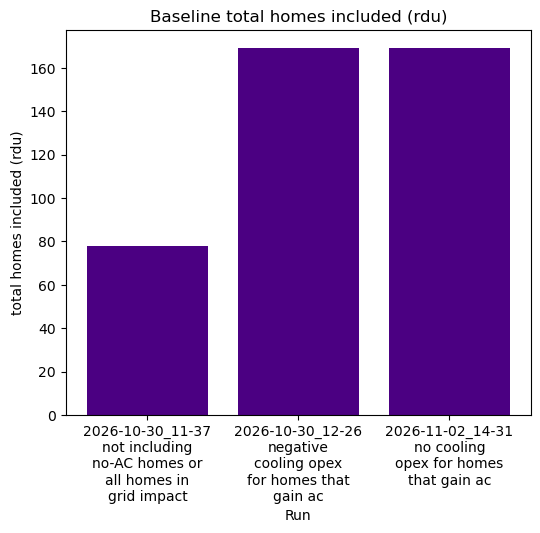

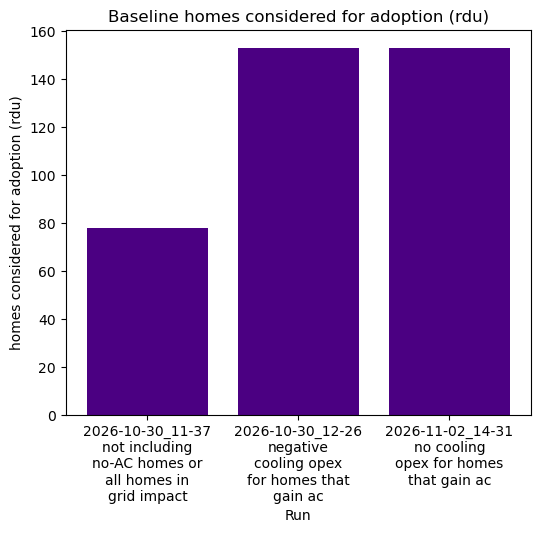

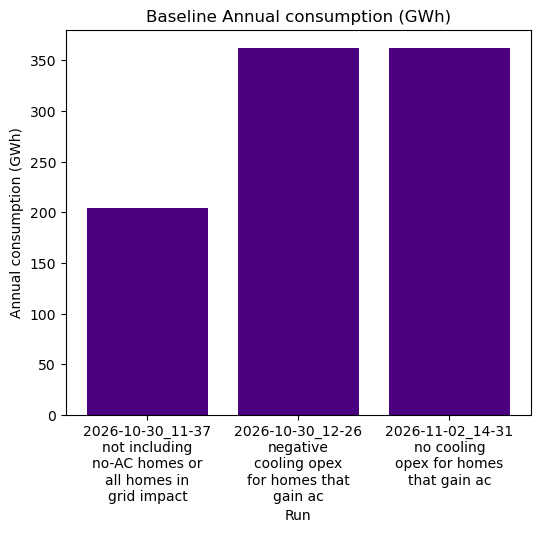

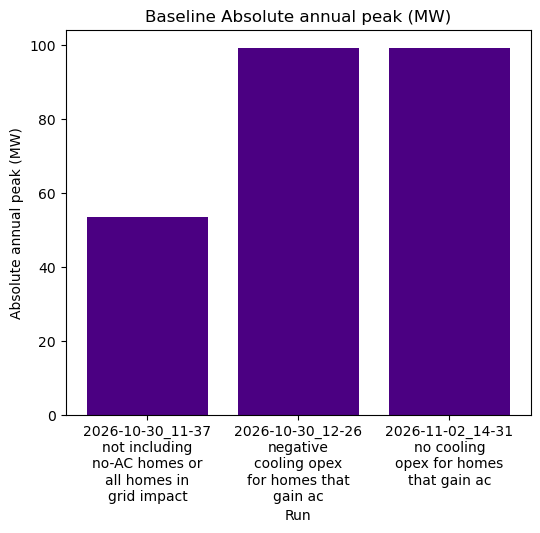

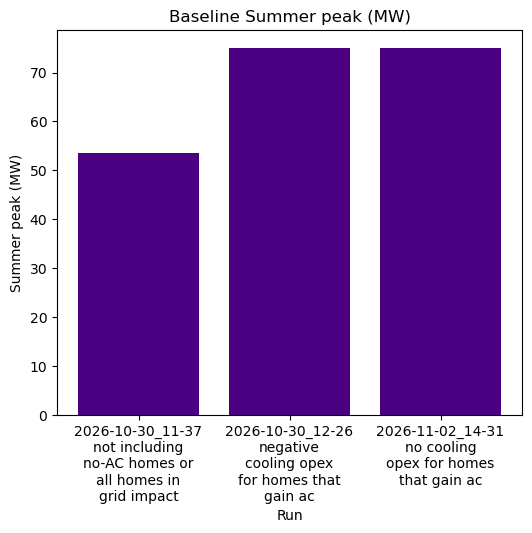

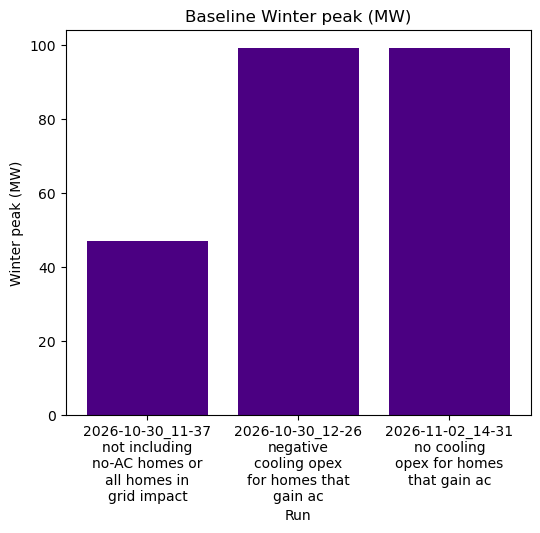

In [19]:

# Bar label: the run's time stamp, then its description
df_baseline["run_label"] = (
    df_baseline["datetime"]
    + "\n"
    + df_baseline["description"].fillna("").apply(
        lambda text: textwrap.fill(text, 14)

    )
)


def plot_energy_data_by_scenario(
        summary_df,
        metric,
        title = "",
        label_col="scenario",
        xlabel="Scenario",
        rotation=90,
        figsize = (8,5)
        ):

    # A new figure each call, so a loop gives one chart per metric
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.bar(summary_df[label_col], summary_df[metric], color='#4B0082')
    ax.set_title(f'{title} {metric}')
    ax.set_ylabel(metric)
    ax.set_xlabel(xlabel)
    ax.tick_params(axis="x", labelrotation=rotation)
    plt.show()


for metric in baseline_metrics:
    plot_energy_data_by_scenario(
        df_baseline, metric, label_col="run_label", xlabel="Run", rotation=0, title = "Baseline"
    )
